In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import ast
from scipy.sparse import csr_matrix



In [2]:
ingr_map = pd.read_pickle("data/ingr_map.pkl")
display(ingr_map)

,raw_ingr,raw_words,processed,len_proc,replaced,count,id
0,"medium heads bibb or red leaf lettuce, washed,...",13,"medium heads bibb or red leaf lettuce, washed,...",73,lettuce,4507,4308
1,mixed baby lettuces and spring greens,6,mixed baby lettuces and spring green,36,lettuce,4507,4308
2,romaine lettuce leaf,3,romaine lettuce leaf,20,lettuce,4507,4308
3,iceberg lettuce leaf,3,iceberg lettuce leaf,20,lettuce,4507,4308
4,red romaine lettuce,3,red romaine lettuce,19,lettuce,4507,4308
...,...,...,...,...,...,...,...
11654,soybeans,1,soybean,7,soybean,31,6702
11655,goose,1,goose,5,goose,8,3318
11656,ajwain,1,ajwain,6,ajwain,13,47
11657,brinjals,1,brinjal,7,brinjal,2,750


In [3]:
# Get all unique ingredients
ingr_map = pd.read_pickle("data/ingr_map.pkl").drop_duplicates("id")
id_to_name = ingr_map.set_index("id")["replaced"]
n_ingr = ingr_map["id"].max() + 1

# How often they are used in the recipes
recipes = pd.read_csv("data/PP_recipes.csv")
recipes["ingredient_ids"] = recipes["ingredient_ids"].apply(ast.literal_eval) # The CSV contains a string instead of a list

rows = np.repeat(np.arange(len(recipes)), recipes["ingredient_ids"].str.len())
cols = np.concatenate(recipes["ingredient_ids"].values)
X = csr_matrix((np.ones(len(rows), dtype=np.int32), (rows, cols)),
               shape=(len(recipes), n_ingr))
X.sum_duplicates()
X.data[:] = 1 

counts = np.asarray(X.sum(axis=0)).ravel()
ingredients = pd.DataFrame({"id": np.arange(n_ingr), "n_recipes": counts})
ingredients["name"] = ingredients["id"].map(id_to_name)

# Then for all ingredients, check how many recipes they share
co = (X.T @ X).tocoo()
mask = (co.row != co.col) & (co.data >= 50)      # drop self-pairs and rare pairs
a, b, both = co.row[mask], co.col[mask], co.data[mask]

# E.g. P(salt|butter) > P(butter|salt), then the direction goes from butter to salt, because butter is more dependant on salt, than salt is on butter.
# #recipes_with_both/#recipes_with_butter > #recipes_with_both/#recipes_with_salt

edges = pd.DataFrame({"src": a, "dst": b, "both": both})
edges["p_dst_given_src"] = both / counts[a]
edges["p_src_given_dst"] = both / counts[b]

# Then keep only the dominant direction of each pair
directed = edges[edges["p_dst_given_src"] > edges["p_src_given_dst"]]

# Even tijdelijke filter, anders ziek grote graph
directed = directed[(directed["src"] > 7000) & (directed["dst"] > 7000)]

G = nx.from_pandas_edgelist(directed, "src", "dst",
                            edge_attr=["both", "p_dst_given_src"],
                            create_using=nx.DiGraph)
nx.set_node_attributes(G, ingredients.set_index("id")["n_recipes"].to_dict(), "n_recipes")
nx.set_node_attributes(G, id_to_name.to_dict(), "name")


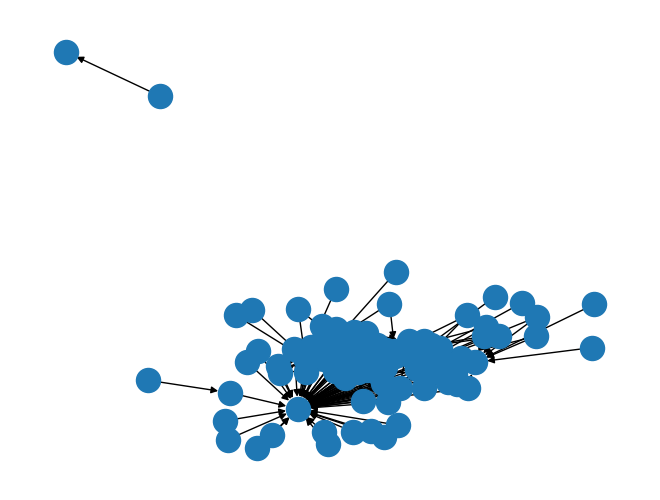

In [4]:
nx.draw(G, pos=nx.spring_layout(G)) # Spring_layout doesn't seem to produce the best positions
plt.show()

In [6]:
# Clustering
U = G.to_undirected()
communities = nx.community.louvain_communities(U, weight="both", resolution=2.0)

min_size = 4
big = [c for c in communities if len(c) >= min_size]
big.sort(key=len, reverse=True)

keep = set().union(*big)
H = G.subgraph(keep).copy()

cluster_of = {n: i for i, c in enumerate(big) for n in c}
nx.set_node_attributes(H, cluster_of, "cluster")

for i, c in enumerate(big[:10]):
    top = sorted(c, key=lambda n: G.nodes[n].get("n_recipes", 0), reverse=True)
    print(f"Cluster {i} ({len(c)} ingredients):")
    print("  ", ", ".join(id_to_name.get(n, str(n)) for n in top))

Cluster 0 (21 ingredients):
   vanilla, vanilla extract, unsalted butter, walnut, white sugar, whipping cream, sweetened condensed milk, whole milk, unsweetened cocoa powder, whipped topping, white chocolate chip, unsweetened cocoa, unbleached flmy, unsweetened chocolate, vegetable shortening, unbleached all-purpose flmy, white chocolate, sweetened flaked coconut, unbaked pie shell, whole wheat pastry flmy, unsweetened chocolate square
Cluster 1 (21 ingredients):
   water, turmeric, vodka, tomato puree, whole clove, tomato soup, white rice, tahini, whole chicken, unflavored gelatin, vegetable, vanilla bean, turnip, wild rice, white bean, tea bag, tamarus, uncooked rice, whole black peppercorn, vegetable bouillon cube, whole allspice
Cluster 2 (16 ingredients):
   tomato, tortilla, swiss cheese, white wine vinegar, white onion, vegetable stock, white bread, taco seasoning, yogurt, whole kernel corn, tuna, whole wheat bread, yellow pepper, turmeric powder, tomatoes and green chily, taco 

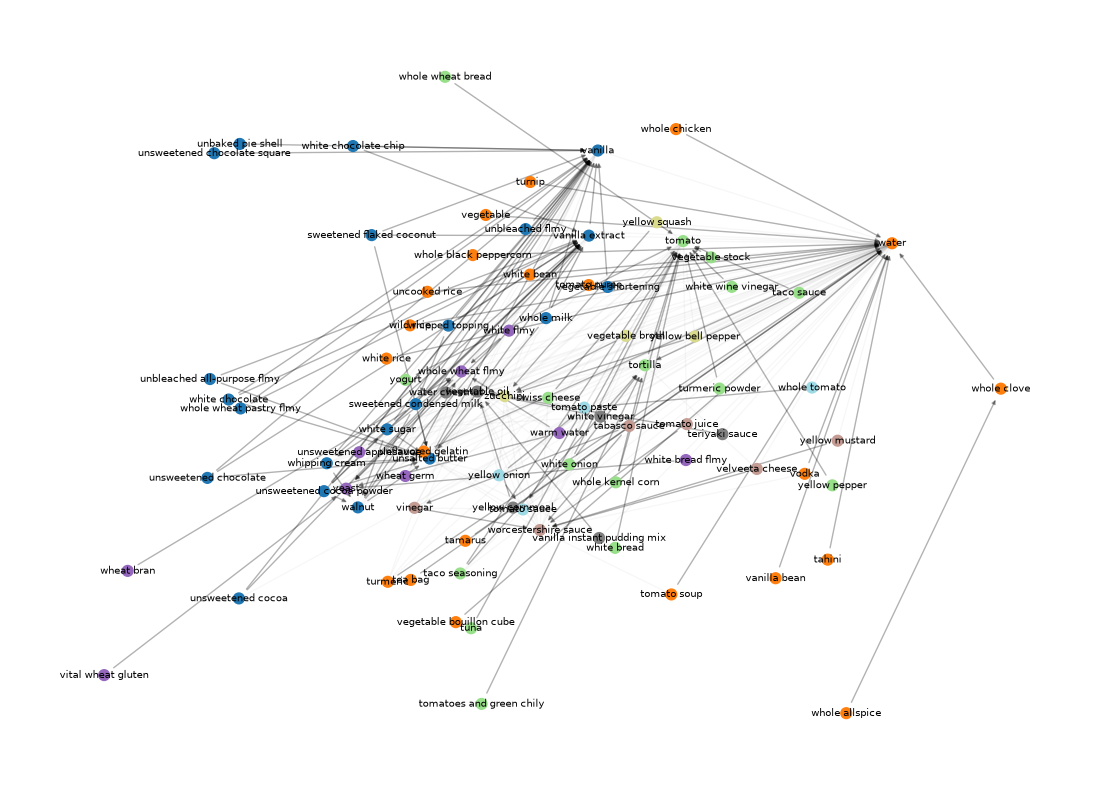

In [ ]:
cl = {n: H.nodes[n]["cluster"] for n in H.nodes}


pos = nx.spring_layout(H)

# Split intra- and intercluster edges
intra = [(u, v) for u, v in H.edges if cl[u] == cl[v]]
inter = [(u, v) for u, v in H.edges if cl[u] != cl[v]]

plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(H, pos, edgelist=inter, alpha=0.03, arrows=False)
nx.draw_networkx_edges(H, pos, edgelist=intra, alpha=0.3, arrowsize=6)
nx.draw_networkx_nodes(H, pos, node_color=[cl[n] for n in H.nodes],
                       cmap="tab20", node_size=60)
nx.draw_networkx_labels(H, pos, font_size=7,
                        labels={n: id_to_name.get(n, str(n)) for n in H.nodes})
plt.axis("off")
plt.show()

# TODO: Cluster geographically, now its still a mess